## **초음파 비파괴검사 실험**

기계시스템공학실험(B) 동제어 2주차

---
`df_full`: Raw Data 중 Full Space에 해당하는 좌표의 데이터

`df_empty`: Raw Data 중 Empty Space에 해당하는 좌표의 데이터

<br><br>

실험 분석을 위해 사용한 라이브러리 및 용도는 다음과 같습니다.


`pandas`: csv 형태의 데이터를 처리하기 위해 사용하였다.

`matplotlib`: Python의 시각화 라이브러리로, 각종 그래프의 시각화를 위해 사용하였다.

`numpy`: 측정한 격자의 형상 시각화를 위해 사용하였다. 

<br><br>
이외 자세한 실험 과정 및 결과는 실험 보고서를 참고 바랍니다.

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import matplotlib

plt.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus'] = False

import xlwings as xw
path = "D:/00 기계공학실험/동제어/초음파_측정/a_0b_0.xlsx"
wb = xw.Book(path)
wb.save(path)
wb.app.quit()

df_tmp = pd.read_excel("D:/00 기계공학실험/동제어/초음파_측정/a_0b_0.xlsx")
display(df_tmp.head())
print(df_tmp.info())

,Untitled
0,0
1,#NV
2,#NV
3,0
4,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12006 entries, 0 to 12005
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Untitled  12006 non-null  object
dtypes: object(1)
memory usage: 93.9+ KB
None




In [ ]:
import warnings
warnings.filterwarnings(action = 'ignore')

# 폴더 경로 설정 
folder_path = r'D:\00 기계공학실험\동제어\초음파_측정'
excel_files = glob.glob(os.path.join(folder_path, '*.xlsx'))

n_files = len(excel_files)
if n_files > 0:
  ncols = 2
  nrows = (n_files + 1) // 2

  fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4 * nrows))
  axes = axes.flatten()  

  for i, file_path in enumerate(excel_files):
    df = pd.read_excel(file_path)
    df = df.replace('#NV', 0)
    df = df.apply(pd.to_numeric, errors='ignore')

    ax = axes[i]

    # 그래프 그리기
    if len(df.columns) >= 2:
      x = df.iloc[:, 0]
      y = df.iloc[:, 1]
      ax.plot(x, y, color='blue', linewidth=1)
    else:
      ax.plot(df.values, color='blue', linewidth=1)

    file_name = os.path.basename(file_path)
    ax.set_title(file_name, fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)

  for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

  plt.tight_layout()
  plt.show()
else:
  print('지정한 폴더에 엑셀 파일이 없습니다.')

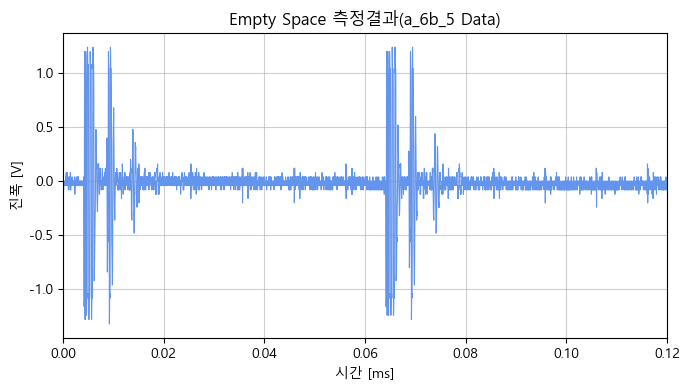

In [ ]:
## Empty Space의 경우

df_empty = pd.read_excel("D:/00 기계공학실험/동제어/초음파_측정/a_6b_5.xlsx")
df_empty = df_empty.replace('#NV', 0)
df_empty = df_empty.apply(pd.to_numeric, errors='ignore')
import warnings
warnings.filterwarnings(action = 'ignore')

time_interval_ms = 10 * 1e-6
plt.figure(figsize=(7, 4))

x = df_empty.index * time_interval_ms

if len(df_empty.columns) >= 2:
  y = df_empty.iloc[:, 1]
else:
  y = df_empty.iloc[:, 0]

plt.plot(x, y, color='cornflowerblue', linewidth=0.8)
plt.title('Empty Space 측정결과(a_6b_5 Data)', fontsize=12)
plt.xlabel('시간 [ms]')
plt.xlim((0,0.12))
plt.ylabel('진폭 [V]')
plt.grid(True, alpha=0.6)
plt.tight_layout()
plt.show()

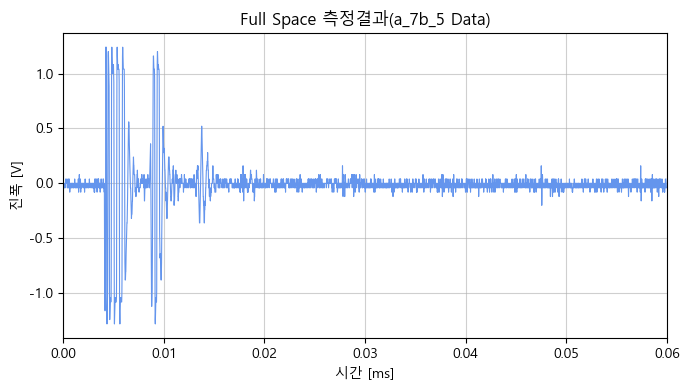

In [ ]:
## Full Space의 경우

df_full = pd.read_excel("D:/00 기계공학실험/동제어/초음파_측정/a_7b_5.xlsx")
df_full = df_full.replace('#NV', 0)
df_full = df_full.apply(pd.to_numeric, errors='ignore')

time_interval_ms = 10 * 1e-6
plt.figure(figsize=(7, 4))

x = df_full.index * time_interval_ms

if len(df_full.columns) >= 2:
  y = df_full.iloc[:, 1]
else:
  y = df_full.iloc[:, 0]

plt.plot(x, y, color='cornflowerblue', linewidth=0.8)
plt.title('Full Space 측정결과(a_7b_5 Data)', fontsize=12)
plt.xlabel('시간 [ms]')
plt.ylabel('진폭 [V]')
plt.grid(True, alpha=0.6)
plt.xlim((0,0.06))
plt.tight_layout()
plt.show()

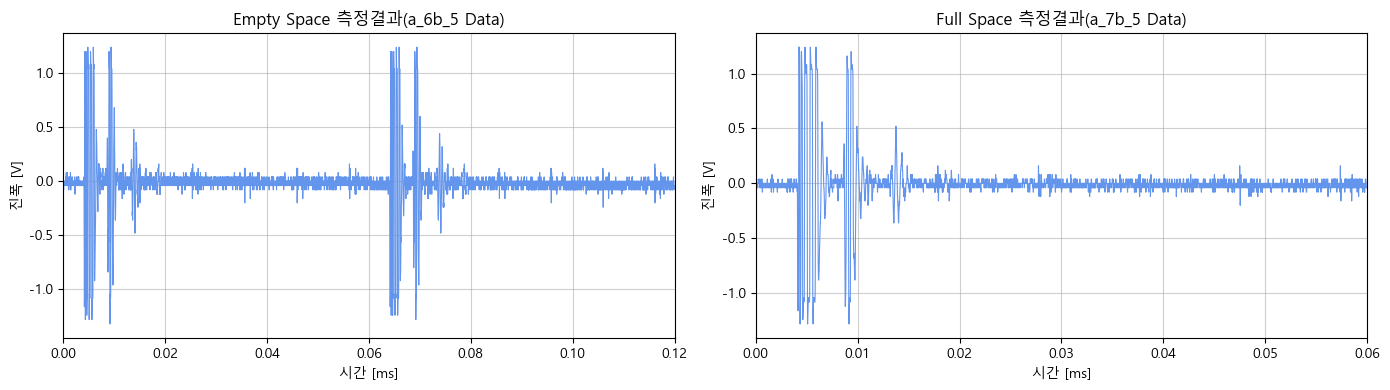

In [ ]:
## 그래프 두 개 병렬 표시
time_interval_ms = 10 * 1e-6
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Full Space
df_full = pd.read_excel('D:/00 기계공학실험/동제어/초음파_측정/a_6b_5.xlsx')
df_full = df_full.replace('#NV', 0)
df_full = df_full.apply(pd.to_numeric, errors='ignore')
x = df_full.index * time_interval_ms
y = df_full.iloc[:, 1] if len(df_full.columns) >= 2 else df_full.iloc[:, 0]

axes[0].plot(x, y, color='cornflowerblue', linewidth=0.8)
axes[0].set_title('Empty Space 측정결과(a_6b_5 Data)', fontsize=12)
axes[0].set_xlabel('시간 [ms]')
axes[0].set_xlim((0, 0.12))
axes[0].set_ylabel('진폭 [V]')
axes[0].grid(True, alpha=0.6)

# Empty Space
df_full = pd.read_excel('D:/00 기계공학실험/동제어/초음파_측정/a_7b_5.xlsx')
df_full = df_full.replace('#NV', 0)
df_full = df_full.apply(pd.to_numeric, errors='ignore')
x = df_full.index * time_interval_ms
y = df_full.iloc[:, 1] if len(df_full.columns) >= 2 else df_full.iloc[:, 0]

axes[1].plot(x, y, color='cornflowerblue', linewidth=0.8)
axes[1].set_title('Full Space 측정결과(a_7b_5 Data)', fontsize=12)
axes[1].set_xlabel('시간 [ms]')
axes[1].set_ylabel('진폭 [V]')
axes[1].grid(True, alpha=0.6)
axes[1].set_xlim((0, 0.06))

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from scipy.signal import find_peaks
time_interval_ms = 10 * 1e-6

# 데이터 전처리용 함수 
def load_and_preprocess(file_path):
  df = pd.read_excel(file_path)
  df = df.replace('#NV', 0)
  df = df.apply(pd.to_numeric, errors='ignore')
  x = df.index.values * time_interval_ms
  y = df.iloc[:, 1] if len(df.columns) >= 2 else df.iloc[:, 0]
  return x, y


## Empty Space의 경우
path_empty = 'D:/00 기계공학실험/동제어/초음파_측정/a_6b_5.xlsx'
x_empty, y_empty = load_and_preprocess(path_empty)

peaks_empty, _ = find_peaks(y_empty, height=1, distance=15)
first_4_indices = peaks_empty[:10]  
peak_times_empty = x_empty[first_4_indices]  

intervals_empty = np.diff(peak_times_empty)
print(f'Empty Space 피크 시간 [ms]: {peak_times_empty}')


## Full Space의 겨우
path_full = 'D:/00 기계공학실험/동제어/초음파_측정/a_7b_5.xlsx'
x_full, y_full = load_and_preprocess(path_full)

peaks_full, _ = find_peaks(y_full, height=1, distance=15)
first_3_indices = peaks_full[:10]  
peak_times_full = x_full[first_3_indices]  

intervals_full = np.diff(peak_times_full)
print(f'Full Space 피크 시간 [ms]: {peak_times_full}')

Empty Space 피크 시간 [ms]: [0.00425 0.00448 0.00482 0.005   0.00536 0.00591 0.00899 0.00939 0.06428
 0.06451]
Full Space 피크 시간 [ms]: [0.00426 0.00448 0.00483 0.00499 0.00536 0.00591 0.00896 0.00936]


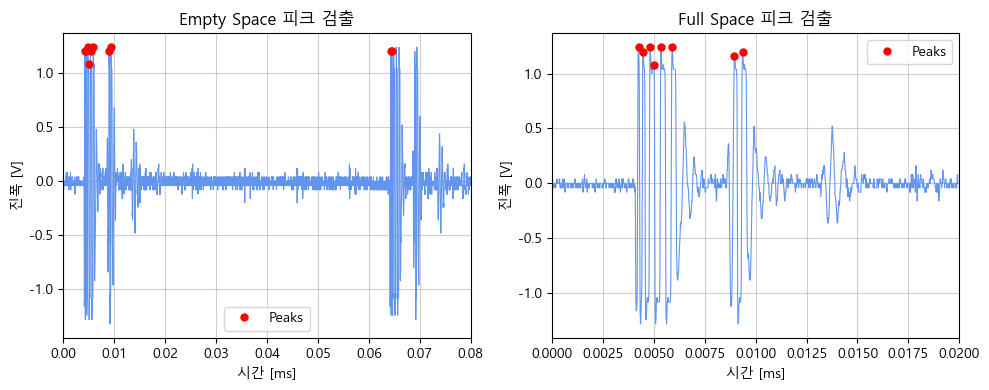

In [ ]:
## 피크 표시
plt.figure(figsize=(10, 4))

# Empty Space 피크 표시
plt.subplot(1, 2, 1)
plt.plot(x_empty, y_empty, color='cornflowerblue', linewidth=0.8)
plt.plot(peak_times_empty, y_empty.iloc[first_4_indices], 'ro', markersize=5, label='Peaks')
plt.title('Empty Space 피크 검출')
plt.xlabel('시간 [ms]')
plt.ylabel('진폭 [V]')
plt.xlim((0,0.08))
plt.grid(True, alpha=0.6)
plt.legend()

# Full Space 피크 표시
plt.subplot(1, 2, 2)
plt.plot(x_full, y_full, color='cornflowerblue', linewidth=0.8)
plt.plot(peak_times_full, y_full.iloc[first_3_indices], 'ro', markersize=5, label='Peaks')
plt.title('Full Space 피크 검출')
plt.xlabel('시간 [ms]')
plt.ylabel('진폭 [V]')
plt.xlim((0,0.02))
plt.grid(True, alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

### **음각으로 새겨진 형상 분석**

초음파로 음각으로 새겨진 형상을 분석한 결과는 다음과 같다. 

10x10 격자와 19x20 격자 (원래는 20x20 격자를 의도하였으나, 측정 오차로 19x20으로 실험하였음)으로 2회 실험하였다.

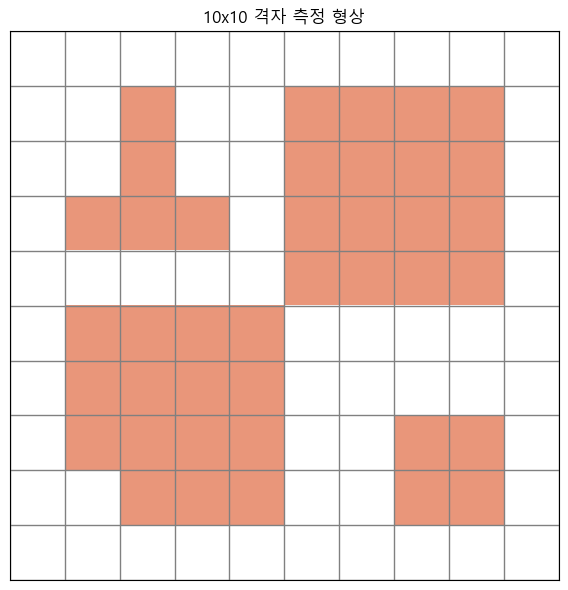

In [ ]:
from matplotlib.colors import ListedColormap

data = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 1, 1, 1, 1, 0],
    [0, 0, 1, 0, 0, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 0, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0, 0, 1, 1, 0],
    [0, 0, 1, 1, 1, 0, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
])

fig, ax = plt.subplots(figsize=(6, 6))

cmap = ListedColormap(['white', 'darksalmon'])
ax.imshow(data, cmap=cmap)

ax.set_xticks(np.arange(-0.5, 10, 1))
ax.set_yticks(np.arange(-0.5, 10, 1))
ax.grid(color='gray', linestyle='-', linewidth=1)

ax.set_xticklabels([])
ax.set_yticklabels([])
ax.tick_params(length=0)

plt.title('10x10 격자 측정 형상', fontsize=12)
plt.tight_layout()
plt.show()

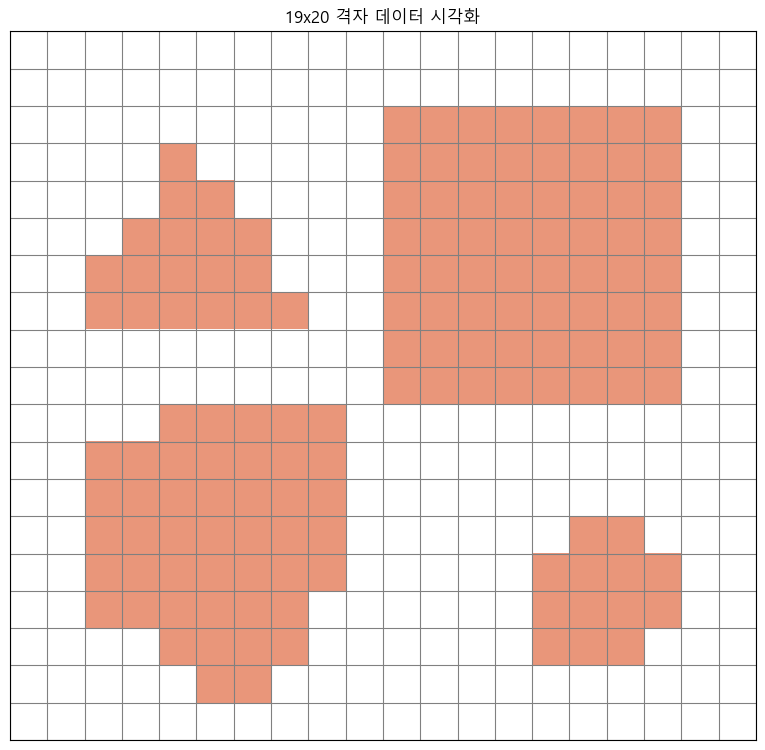

In [ ]:
data2 = np.array([
    [0,0,0,0,0, 0,0,0,0,0, 0,0,0,0,0, 0,0,0,0,0],
    [0,0,0,0,0, 0,0,0,0,0, 0,0,0,0,0, 0,0,0,0,0],
    [0,0,0,0,0, 0,0,0,0,0, 1,1,1,1,1, 1,1,1,0,0],
    [0,0,0,0,1, 0,0,0,0,0, 1,1,1,1,1, 1,1,1,0,0],
    [0,0,0,0,1, 1,0,0,0,0, 1,1,1,1,1, 1,1,1,0,0],
    [0,0,0,1,1, 1,1,0,0,0, 1,1,1,1,1, 1,1,1,0,0],
    [0,0,1,1,1, 1,1,0,0,0, 1,1,1,1,1, 1,1,1,0,0],
    [0,0,1,1,1, 1,1,1,0,0, 1,1,1,1,1, 1,1,1,0,0],
    [0,0,0,0,0, 0,0,0,0,0, 1,1,1,1,1, 1,1,1,0,0],
    [0,0,0,0,0, 0,0,0,0,0, 1,1,1,1,1, 1,1,1,0,0],
    [0,0,0,0,1, 1,1,1,1,0, 0,0,0,0,0, 0,0,0,0,0],
    [0,0,1,1,1, 1,1,1,1,0, 0,0,0,0,0, 0,0,0,0,0],
    [0,0,1,1,1, 1,1,1,1,0, 0,0,0,0,0, 0,0,0,0,0],
    [0,0,1,1,1, 1,1,1,1,0, 0,0,0,0,0, 1,1,0,0,0],
    [0,0,1,1,1, 1,1,1,1,0, 0,0,0,0,1, 1,1,1,0,0],
    [0,0,1,1,1, 1,1,1,0,0, 0,0,0,0,1, 1,1,1,0,0],
    [0,0,0,0,1, 1,1,1,0,0, 0,0,0,0,1, 1,1,0,0,0],
    [0,0,0,0,0, 1,1,0,0,0, 0,0,0,0,0, 0,0,0,0,0],
    [0,0,0,0,0, 0,0,0,0,0, 0,0,0,0,0, 0,0,0,0,0]
])

nrows, ncols = data2.shape
fig, ax = plt.subplots(figsize=(8, 8 * (nrows / ncols)))

cmap = ListedColormap(['white', 'darksalmon'])
ax.imshow(data2, cmap=cmap)
ax.set_xticks(np.arange(-0.5, ncols, 1))
ax.set_yticks(np.arange(-0.5, nrows, 1))
ax.grid(color='gray', linestyle='-', linewidth=0.8)

ax.set_xticklabels([])
ax.set_yticklabels([])
ax.tick_params(length=0)

plt.title('19x20 격자 측정 형상', fontsize=12)
plt.tight_layout()
plt.show()


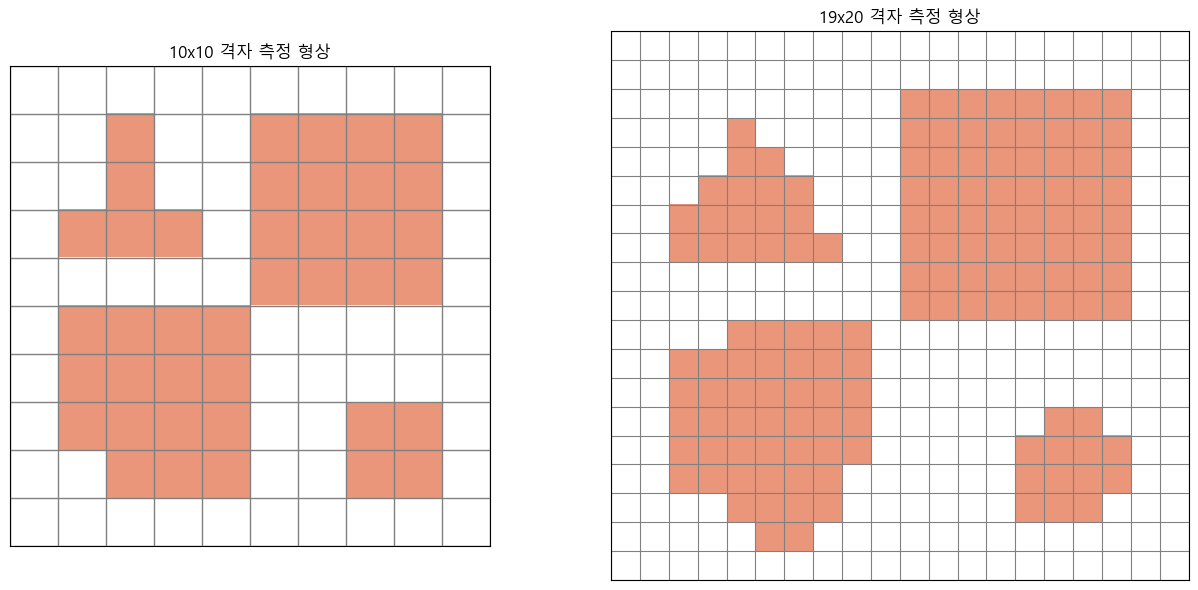

In [42]:
# 두 그래프 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 6), width_ratios=[10, 20])

cmap1 = ListedColormap(['white', 'darksalmon'])
axes[0].imshow(data, cmap=cmap1)

axes[0].set_xticks(np.arange(-0.5, 10, 1))
axes[0].set_yticks(np.arange(-0.5, 10, 1))
axes[0].grid(color='gray', linestyle='-', linewidth=1)

axes[0].set_xticklabels([])
axes[0].set_yticklabels([])
axes[0].tick_params(length=0)
axes[0].set_title('10x10 격자 측정 형상', fontsize=12)

nrows, ncols = data2.shape
cmap2 = ListedColormap(['white', 'darksalmon'])
axes[1].imshow(data2, cmap=cmap2)

axes[1].set_xticks(np.arange(-0.5, ncols, 1))
axes[1].set_yticks(np.arange(-0.5, nrows, 1))
axes[1].grid(color='gray', linestyle='-', linewidth=0.8)

axes[1].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].tick_params(length=0)
axes[1].set_title('19x20 격자 측정 형상', fontsize=12)

plt.tight_layout()
plt.show()